In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Criei funções de todas as fórmulas que serão utilizadas

In [2]:
def media_estimativas(estimativas):

    return np.mean(estimativas)

def vies_empirico(estimativas, theta_0):

    return media_estimativas(estimativas) - theta_0

def variancia_empirica(estimativas):
   
    return np.var(estimativas)

def eqm_empirico(estimativas, theta_0):
   
    estimativas_array = np.array(estimativas)
    return np.mean((estimativas_array - theta_0)**2)

Criando a seed e definindo os parâmetros verdadeiros

In [3]:
np.random.seed(67)
mi = 5
sigma2 = 1
n_50 = 50

(array([2., 0., 3., 1., 7., 6., 5., 3., 4., 3., 7., 3., 3., 1., 2.]),
 array([2.61143463, 2.8923697 , 3.17330477, 3.45423984, 3.73517491,
        4.01610998, 4.29704505, 4.57798012, 4.85891518, 5.13985025,
        5.42078532, 5.70172039, 5.98265546, 6.26359053, 6.5445256 ,
        6.82546067]),
 <BarContainer object of 15 artists>)

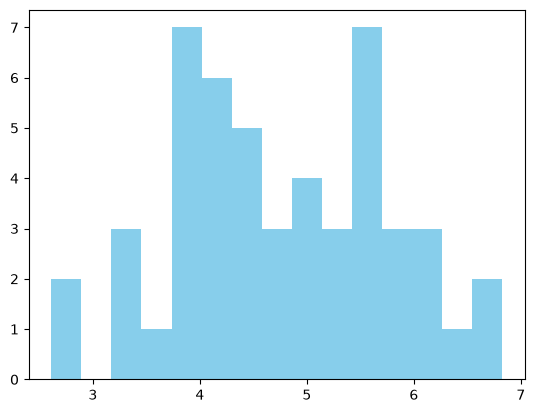

In [4]:
amostra_normal_50 = np.random.normal(mi,sigma2,n_50)
plt.hist(amostra_normal_50,bins=15,color="skyblue")

Sabemos que pelo método da verssimilhança o estimador para a média é a média amostral e para a variância é a variância amostral dividida por n

In [5]:
mi_mmv_50 = sum(amostra_normal_50)/n_50
var_mmv_50 = np.var(amostra_normal_50)
print(f'Os estimadores de máxima verossimilhança para a média e a variância são, respectivamente {mi_mmv_50} e {var_mmv_50}')

Os estimadores de máxima verossimilhança para a média e a variância são, respectivamente 4.789199557630256 e 1.0079175395900912


Aqui geramos as 9 amostras das normais com mi = 5 e sigma2 = 1 de tamanho 50.

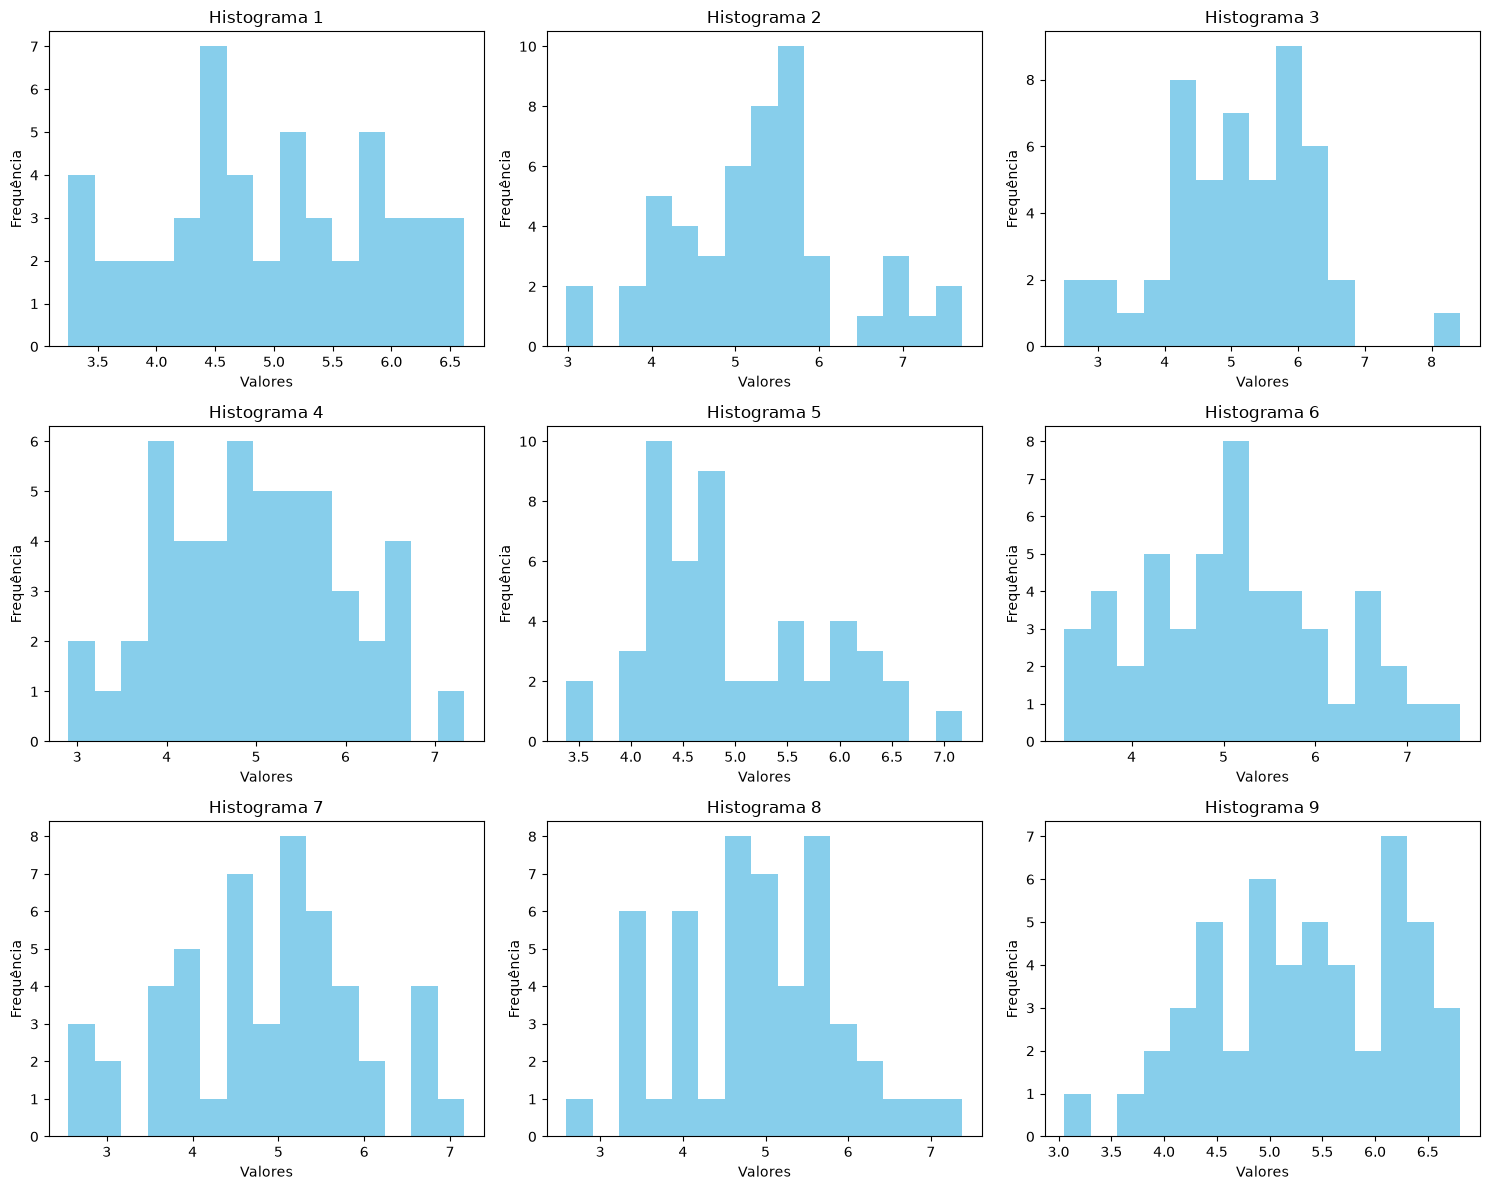

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
medias = [mi_mmv_50]
vars = [var_mmv_50]
axes = axes.flatten()

for i in range(9):
    np.random.seed(100 + i)
    

    dados = np.random.normal(5, 1,size= n_50)
    media = np.mean(dados)
    var = np.var(dados)
    medias.append(media)
    vars.append(var)
    

    axes[i].hist(dados, bins=15, color='skyblue')
    
    axes[i].set_title(f'Histograma {i+1}')
    axes[i].set_xlabel('Valores')
    axes[i].set_ylabel('Frequência')


plt.tight_layout()


plt.show() 

Aqui fizemos as tabelas com as médias e variâncias de cada amostra.

In [7]:
nomes_amostras = [f'{i+1}ª Amostra' for i in range(len(medias))]
tabela_50 = pd.DataFrame({
    'Médias': medias,
    'Variâncias': vars,
}, index=nomes_amostras)
tabela_50


,Médias,Variâncias
1ª Amostra,4.789200,1.007918
2ª Amostra,4.959199,0.885895
3ª Amostra,5.268114,1.054789
4ª Amostra,5.097030,1.240000
5ª Amostra,4.999974,1.005902
6ª Amostra,4.982601,0.699685
7ª Amostra,5.132228,1.098582
8ª Amostra,4.830735,1.193433
9ª Amostra,4.899121,0.964909
10ª Amostra,5.315679,0.807212


Aqui calculamos as estimativas para a média e variância.

In [8]:
# Média das estimativas
media_medias = media_estimativas(medias)
media_variancias = media_estimativas(vars)

# Viéses empíricos
vies_emp_medias = vies_empirico(medias, 5)
vies_emp_variancias = vies_empirico(vars, 1)

# Variâncias empíricas
var_emp_medias = variancia_empirica(medias)
var_emp_variancias = variancia_empirica(vars)

# EQM empírico
eqm_emp_medias = eqm_empirico(medias, 5)
eqm_emp_var = eqm_empirico(vars, 1)


# EQM = Variancias empiricas + vieses^2
eqm_formula_medias = var_emp_medias + vies_emp_medias**2
eqm_formula_variancias = var_emp_variancias + vies_emp_variancias**2

Aqui criamos as tabelas com as estimativas

In [9]:
dados_tabela = {
    'Média das Estimativas': [media_medias, media_variancias],
    'Viés Empírico': [vies_emp_medias, vies_emp_variancias],
    'Variância Empírica': [var_emp_medias, var_emp_variancias],
    'EQM Empírico': [eqm_emp_medias, eqm_emp_var],
    'EQM Fórmula': [eqm_formula_medias, eqm_formula_variancias],
    'Valor Verdadeiro' : [mi, sigma2]
}

# Cria o DataFrame definindo os nomes das linhas (índices)
tabela_resultados_50 = pd.DataFrame(
    dados_tabela, 
    index=['Estimativas da Média (μ)', 'Estimativas da Variância (σ²)']
)
tabela_resultados_50

,Média das Estimativas,Viés Empírico,Variância Empírica,EQM Empírico,EQM Fórmula,Valor Verdadeiro
Estimativas da Média (μ),5.027388,0.027388,0.027617,0.028367,0.028367,5
Estimativas da Variância (σ²),0.995832,-0.004168,0.024927,0.024944,0.024944,1


Quando olhamos para o viés teórico do estimador X barra (média amostral), sabemos que ele é não viesado, mas quando olhamos para a estimativa, o viés pode sim aparecer

# Fazendo o exercício 2 (n=200)

(array([ 4., 15., 24., 34., 42., 26., 27., 20.,  4.,  4.]),
 array([2.47679562, 2.98114603, 3.48549645, 3.98984687, 4.49419728,
        4.9985477 , 5.50289812, 6.00724853, 6.51159895, 7.01594937,
        7.52029978]),
 <BarContainer object of 10 artists>)

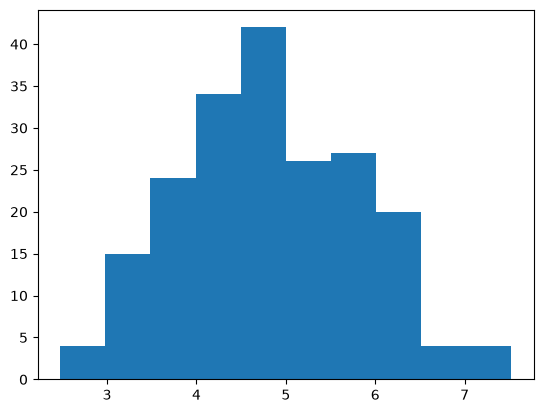

In [27]:
n_200 = 200
mi = 5
sigma2 = 1
amostra_normal_200 = np.random.normal(mi,sigma2,size = n_200)
plt.hist(amostra_normal_200)

In [12]:
mi_mmv_200 = np.mean(amostra_normal_200)
var_mmv_200 = np.var(amostra_normal_200)
print(f'A estimativa da média pelo método da máxima verossimilhança é {mi_mmv_200} e a estimativa da variânicia pelo método da máxima verossimilhança é {var_mmv_200}')

A estimativa da média pelo método da máxima verossimilhança é 5.077357895946772 e a estimativa da variânicia pelo método da máxima verossimilhança é 0.8208951273924545


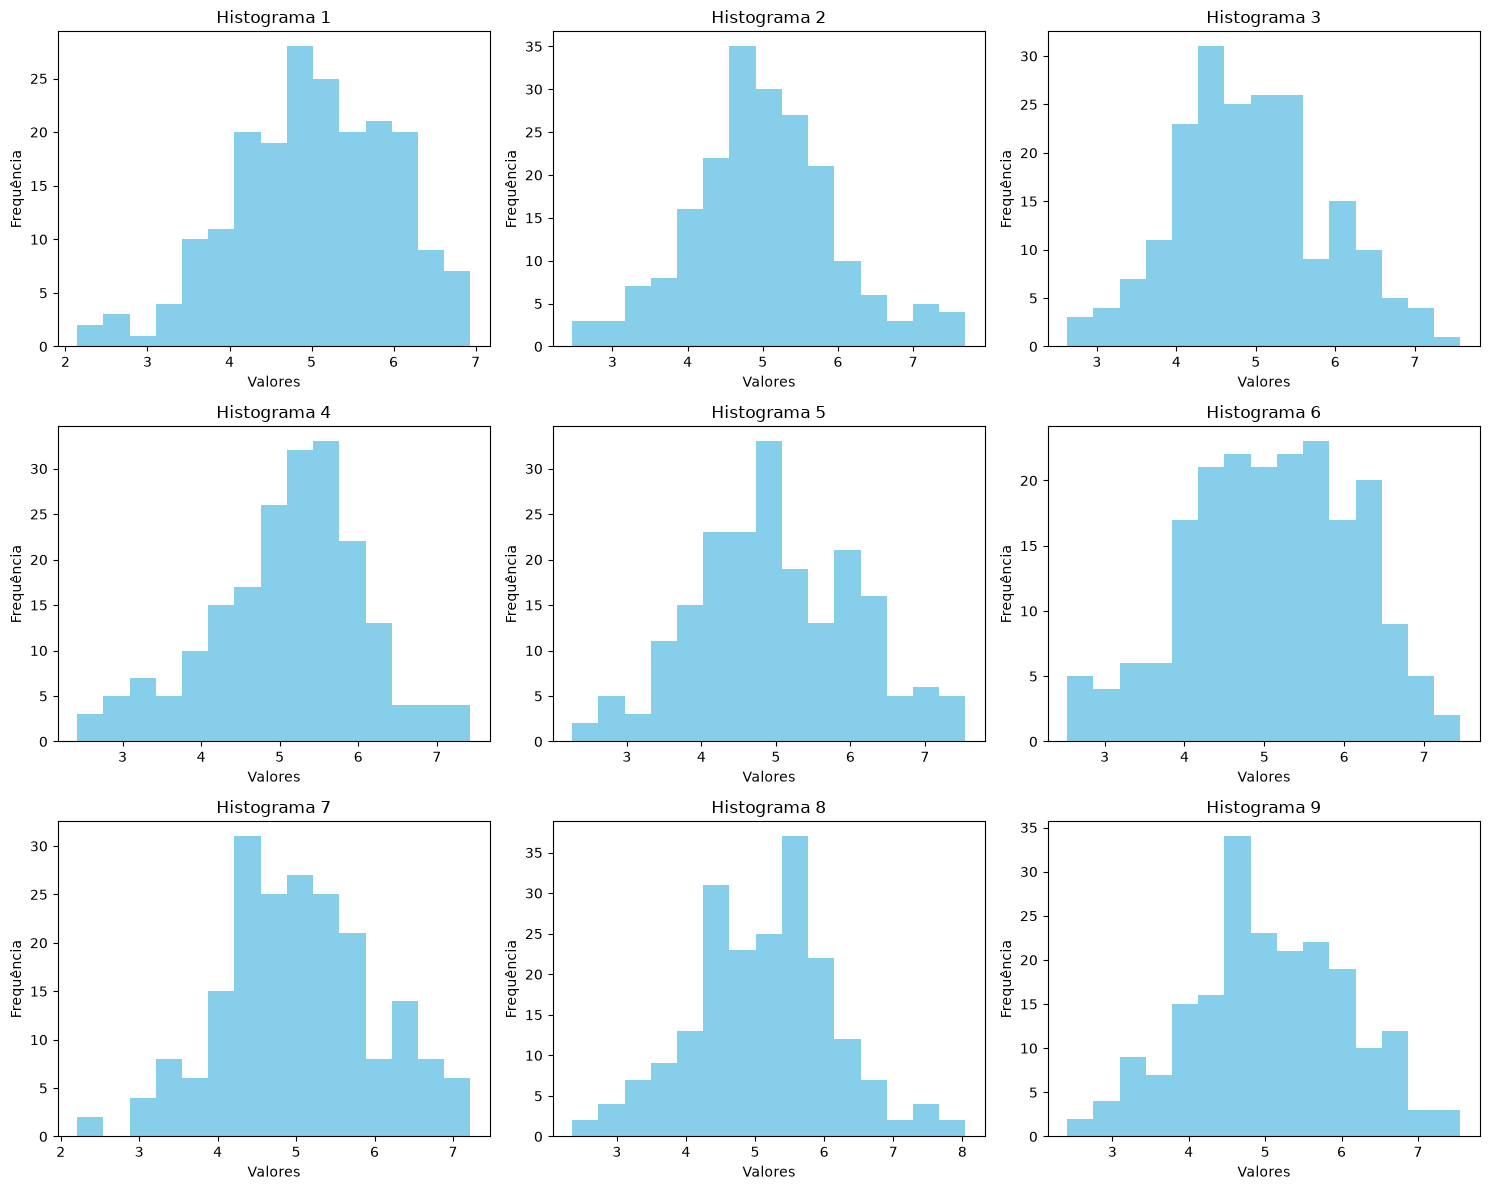

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
medias_200 = [mi_mmv_200]
vars_200 = [var_mmv_200]
axes = axes.flatten()

for i in range(9):
    np.random.seed(110 + i)
    

    dados_200 = np.random.normal(mi, sigma2,size= n_200)
    media1 = np.mean(dados_200)
    var1 = np.var(dados_200)
    medias_200.append(media1)
    vars_200.append(var1)
    

    axes[i].hist(dados_200, bins=15, color='skyblue')
    
    axes[i].set_title(f'Histograma {i+1}')
    axes[i].set_xlabel('Valores')
    axes[i].set_ylabel('Frequência')


plt.tight_layout()
plt.show()

In [14]:
nomes_amostras = [f'{i+1}ª Amostra' for i in range(len(medias_200))]
tabela_200 = pd.DataFrame({
    'Médias': medias_200,
    'Variâncias': vars_200,
}, index=nomes_amostras)
tabela_200

,Médias,Variâncias
1ª Amostra,5.077358,0.820895
2ª Amostra,5.015060,0.938601
3ª Amostra,5.011422,0.948285
4ª Amostra,4.943534,0.886761
5ª Amostra,5.107588,0.930607
6ª Amostra,4.990876,1.137462
7ª Amostra,5.087998,1.073655
8ª Amostra,5.031483,0.932421
9ª Amostra,5.113529,1.013474
10ª Amostra,5.055834,1.079174


In [15]:
# Média das estimativas
media_medias_200 = media_estimativas(medias_200)
media_variancias_200 = media_estimativas(vars_200)

# Viéses empíricos
vies_emp_medias_200 = vies_empirico(medias_200, 5)
vies_emp_variancias_200 = vies_empirico(vars_200, 1)

# Variâncias empíricas
var_emp_medias_200 = variancia_empirica(medias_200)
var_emp_variancias_200 = variancia_empirica(vars_200)

# EQM empírico
eqm_emp_medias_200 = eqm_empirico(medias_200, 5)
eqm_emp_var_200 = eqm_empirico(vars_200, 1)


# EQM = Variancias empiricas + vieses^2
eqm_formula_medias_200 = var_emp_medias_200 + vies_emp_medias_200**2
eqm_formula_variancias_200 = var_emp_variancias_200 + vies_emp_variancias_200**2

In [16]:
dados_tabela = {
    'Média das Estimativas': [media_medias_200, media_variancias_200],
    'Viés Empírico': [vies_emp_medias_200, vies_emp_variancias_200],
    'Variância Empírica': [var_emp_medias_200, var_emp_variancias_200],
    'EQM Empírico': [eqm_emp_medias_200, eqm_emp_var_200],
    'EQM Fórmula': [eqm_formula_medias_200, eqm_formula_variancias_200],
    'Valor Verdadeiro' : [mi, sigma2]
}

# Cria o DataFrame definindo os nomes das linhas (índices)
tabela_resultados_200 = pd.DataFrame(
    dados_tabela, 
    index=['Estimativas da Média (μ)', 'Estimativas da Variância (σ²)']
)
tabela_resultados_200

,Média das Estimativas,Viés Empírico,Variância Empírica,EQM Empírico,EQM Fórmula,Valor Verdadeiro
Estimativas da Média (μ),5.043468,0.043468,0.002703,0.004593,0.004593,5
Estimativas da Variância (σ²),0.976134,-0.023866,0.008580,0.009150,0.009150,1


In [17]:
dados_tabela = {
    'Média das Estimativas': [media_medias, media_variancias, media_medias_200, media_variancias_200],
    'Viés Empírico': [vies_emp_medias, vies_emp_variancias, vies_emp_medias_200, vies_emp_variancias_200],
    'Variância Empírica': [var_emp_medias, var_emp_variancias, var_emp_medias_200, var_emp_variancias_200],
    'EQM Empírico': [eqm_emp_medias, eqm_emp_var, eqm_emp_medias_200, eqm_emp_var_200],
    'EQM Fórmula': [eqm_formula_medias, eqm_formula_variancias, eqm_formula_medias_200, eqm_formula_variancias_200],
    'Valor Verdadeiro' : [mi, sigma2, mi, sigma2]
}

# Cria o DataFrame com n=50 no topo e n=200 logo abaixo
tabela_comparativa = pd.DataFrame(
    dados_tabela, 
    index=[
        'Estimativas da Média (μ) [n=50]', 
        'Estimativas da Variância (σ²) [n=50]',
        'Estimativas da Média (μ) [n=200]', 
        'Estimativas da Variância (σ²) [n=200]'
    ]
)
tabela_comparativa

,Média das Estimativas,Viés Empírico,Variância Empírica,EQM Empírico,EQM Fórmula,Valor Verdadeiro
Estimativas da Média (μ) [n=50],5.027388,0.027388,0.027617,0.028367,0.028367,5
Estimativas da Variância (σ²) [n=50],0.995832,-0.004168,0.024927,0.024944,0.024944,1
Estimativas da Média (μ) [n=200],5.043468,0.043468,0.002703,0.004593,0.004593,5
Estimativas da Variância (σ²) [n=200],0.976134,-0.023866,0.008580,0.009150,0.009150,1


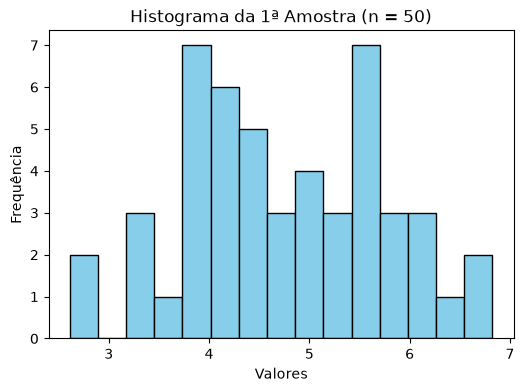

In [18]:
plt.figure(figsize=(6, 4))
plt.hist(amostra_normal_50, bins=15, color="skyblue", edgecolor="black")
plt.title("Histograma da 1ª Amostra (n = 50)")
plt.xlabel("Valores")
plt.ylabel("Frequência")
plt.savefig('histograma_50.pdf', bbox_inches='tight')
plt.show()

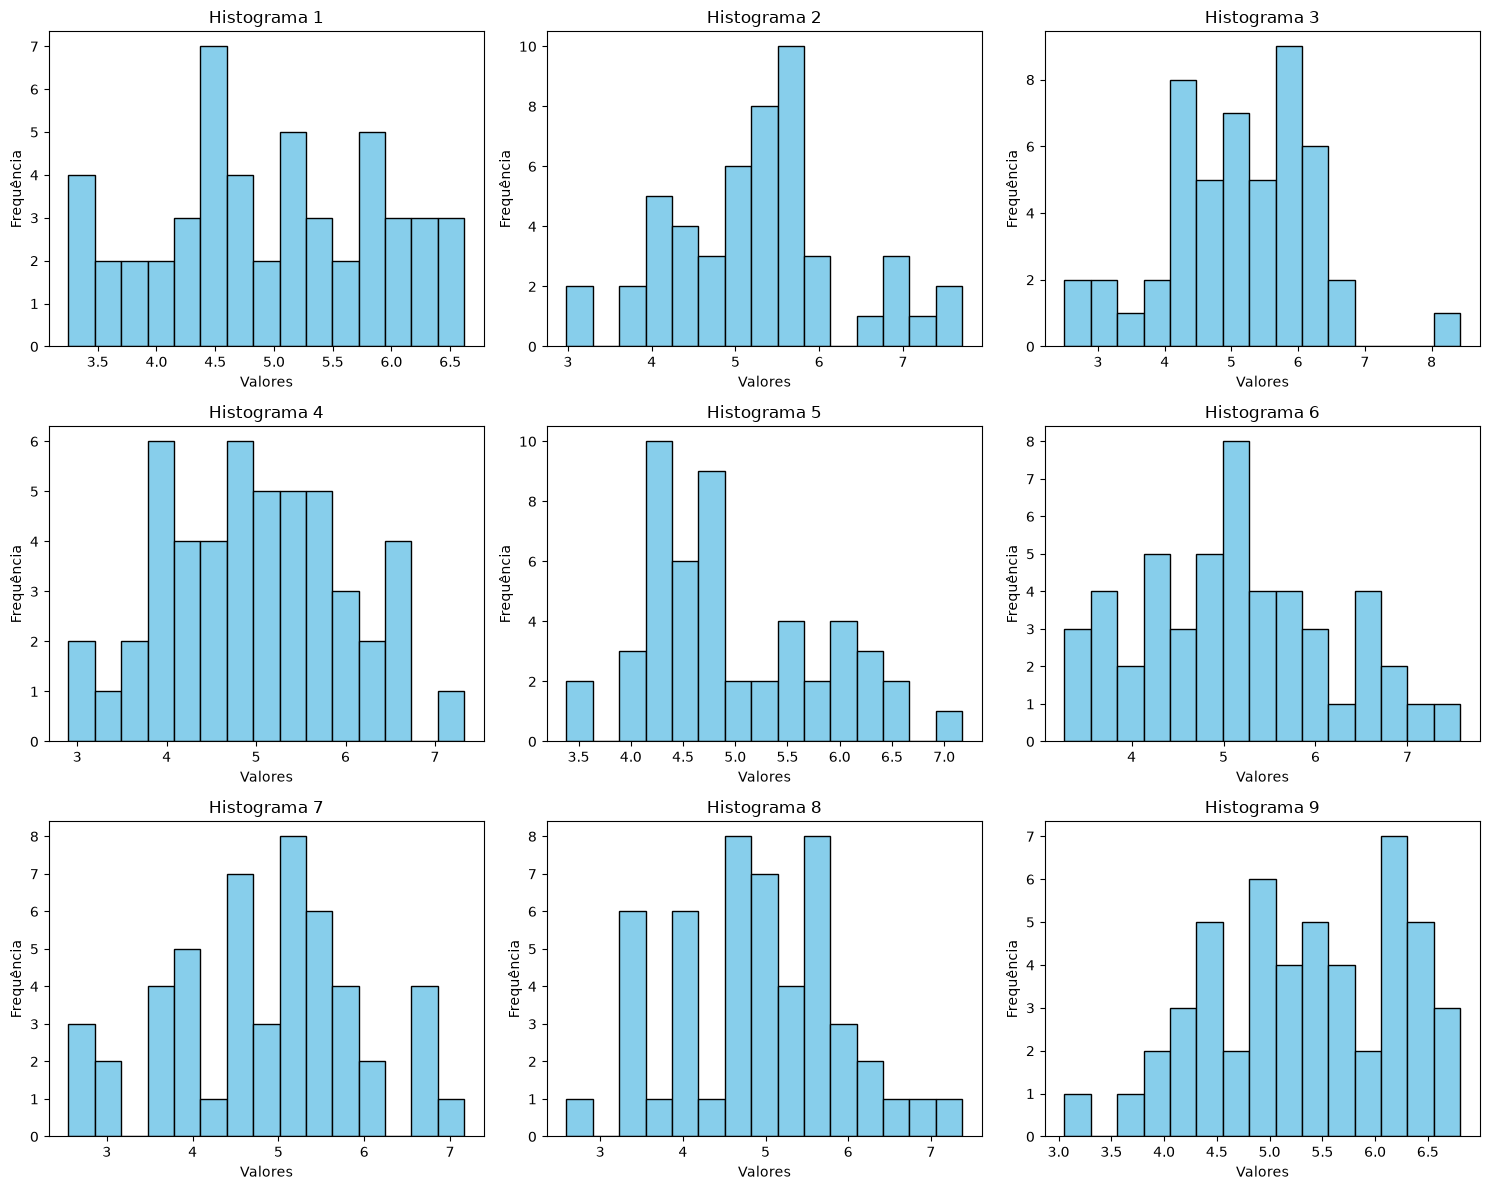

In [19]:
fig_50, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i in range(9):
    np.random.seed(100 + i)
    dados = np.random.normal(5, 1, size=n_50)
    axes[i].hist(dados, bins=15, color='skyblue', edgecolor="black")
    axes[i].set_title(f'Histograma {i+1}')
    axes[i].set_xlabel('Valores')
    axes[i].set_ylabel('Frequência')

plt.tight_layout()
fig_50.savefig('grade_histogramas.pdf', bbox_inches='tight')
plt.show()

In [20]:
nomes_amostras_50 = [f'{i+1}ª Amostra' for i in range(len(medias))]

tabela_50 = pd.DataFrame({
    'Médias': medias,
    'Variâncias': vars,
}, index=nomes_amostras_50)

tabela_50.to_latex('tabela_amostras.tex', index=True, float_format="%.4f")
tabela_50

,Médias,Variâncias
1ª Amostra,4.789200,1.007918
2ª Amostra,4.959199,0.885895
3ª Amostra,5.268114,1.054789
4ª Amostra,5.097030,1.240000
5ª Amostra,4.999974,1.005902
6ª Amostra,4.982601,0.699685
7ª Amostra,5.132228,1.098582
8ª Amostra,4.830735,1.193433
9ª Amostra,4.899121,0.964909
10ª Amostra,5.315679,0.807212


In [21]:
media_medias = media_estimativas(medias)
media_variancias = media_estimativas(vars)
vies_emp_medias = vies_empirico(medias, 5)
vies_emp_variancias = vies_empirico(vars, 1)
var_emp_medias = variancia_empirica(medias)
var_emp_variancias = variancia_empirica(vars)
eqm_emp_medias = eqm_empirico(medias, 5)
eqm_emp_var = eqm_empirico(vars, 1)
eqm_formula_medias = var_emp_medias + vies_emp_medias**2
eqm_formula_variancias = var_emp_variancias + vies_emp_variancias**2

dados_tabela_50 = {
    'Média das Estimativas': [media_medias, media_variancias],
    'Viés Empírico': [vies_emp_medias, vies_emp_variancias],
    'Variância Empírica': [var_emp_medias, var_emp_variancias],
    'EQM Empírico': [eqm_emp_medias, eqm_emp_var],
    'EQM Fórmula': [eqm_formula_medias, eqm_formula_variancias],
    'Valor Verdadeiro': [mi, sigma2]
}

tabela_resultados_50 = pd.DataFrame(
    dados_tabela_50,
    index=['Estimativas da Média', 'Estimativas da Variância']
)

tabela_resultados_50.to_latex('tabela_resultados.tex', index=True, float_format="%.4f")
tabela_resultados_50

,Média das Estimativas,Viés Empírico,Variância Empírica,EQM Empírico,EQM Fórmula,Valor Verdadeiro
Estimativas da Média,5.027388,0.027388,0.027617,0.028367,0.028367,5
Estimativas da Variância,0.995832,-0.004168,0.024927,0.024944,0.024944,1


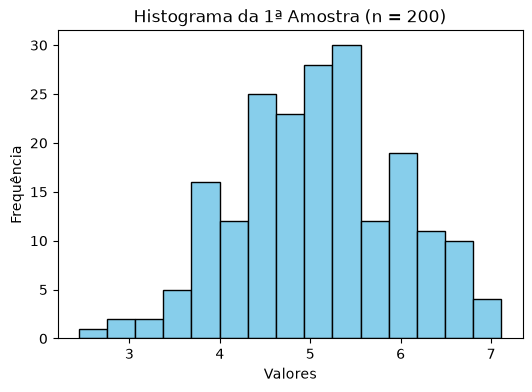

In [22]:
plt.figure(figsize=(6, 4))
plt.hist(amostra_normal_200, bins=15, color="skyblue")
plt.title("Histograma da 1ª Amostra (n = 200)")
plt.xlabel("Valores")
plt.ylabel("Frequência")
plt.savefig('histograma_200.pdf', bbox_inches='tight')
plt.show()